In [ ]:

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

train = pd.read_csv('trainrice.csv', parse_dates=['date'])
test = pd.read_csv('testrice.csv', parse_dates=['date'])
targets = ['dki_jakarta', 'jawa_tengah', 'jawa_timur']
print('train:', train.shape, train['date'].min(), '-', train['date'].max())
print('test :', test.shape, test['date'].min(), '-', test['date'].max())
print(train.isna().sum().to_string())
train.head(10)

c:\Users\2020d\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


train: (627, 5) 2021-01-05 00:00:00 - 2023-05-31 00:00:00
test : (157, 2) 2023-06-01 00:00:00 - 2024-01-05 00:00:00
id              0
date            0
dki_jakarta    27
jawa_tengah    26
jawa_timur     25


,id,date,dki_jakarta,jawa_tengah,jawa_timur
0,0,2021-01-05,13450.0,10950.0,10500.0
1,1,2021-01-06,13450.0,10950.0,10500.0
2,2,2021-01-07,13450.0,10950.0,10500.0
3,3,2021-01-08,13450.0,10950.0,10500.0
4,4,2021-01-11,13450.0,10950.0,10500.0
5,5,2021-01-12,13450.0,10950.0,10500.0
6,6,2021-01-13,13450.0,10950.0,10500.0
7,7,2021-01-14,13450.0,10950.0,10500.0
8,8,2021-01-15,13450.0,10950.0,10500.0
9,9,2021-01-18,13450.0,10950.0,10500.0


pct hari harga tetap:
dki_jakarta 87.2 %  n_unique: 34
jawa_tengah 86.1 %  n_unique: 40
jawa_timur 84.8 %  n_unique: 42
         dki_jakarta  jawa_tengah  jawa_timur
ym                                           
2022-06      13386.0      10950.0     10482.0
2022-07      13450.0      10948.0     10493.0
2022-08      13476.0      11057.0     10696.0
2022-09      13591.0      11270.0     10918.0
2022-10      13750.0      11352.0     11160.0
2022-11      13823.0      11409.0     11305.0
2022-12      13982.0      11814.0     11641.0
2023-01      14155.0      12166.0     11818.0
2023-02      14448.0      12660.0     12190.0
2023-03      14439.0      12696.0     12043.0
2023-04      14445.0      12618.0     12128.0
2023-05      14417.0      12641.0     12126.0


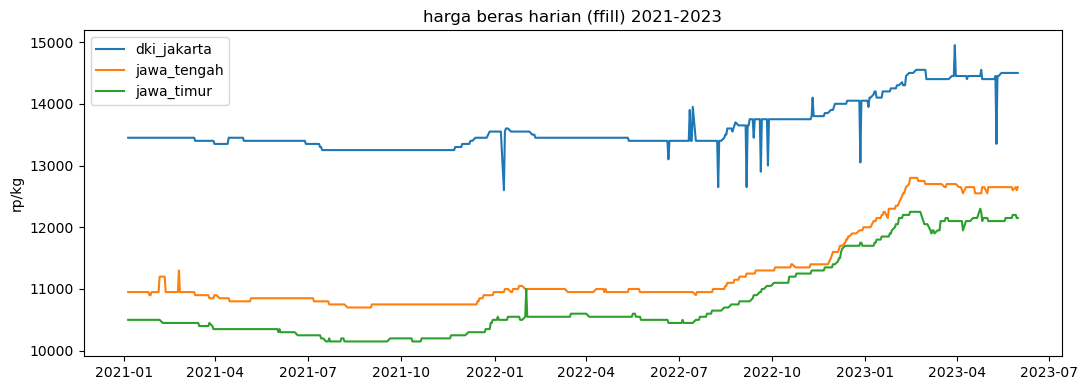

weekday train: {0: 125, 1: 126, 2: 126, 3: 125, 4: 125}
weekday test : {0: 31, 1: 31, 2: 31, 3: 32, 4: 32}
contoh tanggal hilang (libur nasional):
      id       date
28    28 2021-02-12
47    47 2021-03-11
63    63 2021-04-02
91    91 2021-05-12
92    92 2021-05-13
93    93 2021-05-14
101  101 2021-05-26
105  105 2021-06-01
140  140 2021-07-20
156  156 2021-08-11


In [ ]:

tmp = train.copy()
for c in targets:
    tmp[c] = tmp[c].ffill()
print('pct hari harga tetap:')
for c in targets:
    print(c, round((tmp[c].diff() == 0).mean() * 100, 1), '%  n_unique:', tmp[c].nunique())

tmp['ym'] = tmp['date'].dt.to_period('M')
print(tmp.groupby('ym')[targets].mean().tail(12).round(0).to_string())

fig, ax = plt.subplots(figsize=(11, 4))
for c in targets:
    ax.plot(tmp['date'], tmp[c], label=c)
ax.legend(); ax.set_title('harga beras harian (ffill) 2021-2023')
ax.set_ylabel('rp/kg'); plt.tight_layout(); plt.show()

# distribusi weekday: hanya senin-jumat (data bisnis harian)
print('weekday train:', pd.to_datetime(train['date']).dt.dayofweek.value_counts().sort_index().to_dict())
print('weekday test :', pd.to_datetime(test['date']).dt.dayofweek.value_counts().sort_index().to_dict())
print('contoh tanggal hilang (libur nasional):')
print(train[train[targets].isna().any(axis=1)][['id', 'date']].head(10).to_string())

In [ ]:

df = train.sort_values('id').reset_index(drop=True).copy()
for c in targets:
    df[c] = df[c].ffill().bfill()
print('sisa nan:', int(df[targets].isna().sum().sum()))
print('nilai terakhir train:')
print(df[['date'] + targets].tail(3).to_string(index=False))
LAGS, WINS = [1, 2, 3, 5, 10, 20], [5, 20]
def make_features(d):
    d = d.copy()
    d['t'] = np.arange(len(d))
    d['dow'] = pd.to_datetime(d['date']).dt.dayofweek
    d['month'] = pd.to_datetime(d['date']).dt.month
    for c in targets:
        for L in LAGS:
            d[f'{c}_lag{L}'] = d[c].shift(L)
        for W in WINS:
            d[f'{c}_ma{W}'] = d[c].shift(1).rolling(W).mean()
    return d.dropna().reset_index(drop=True)

sisa nan: 0
nilai terakhir train:
      date  dki_jakarta  jawa_tengah  jawa_timur
2023-05-29      14500.0      12650.0     12200.0
2023-05-30      14500.0      12600.0     12150.0
2023-05-31      14500.0      12650.0     12150.0


In [ ]:

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
def mae(a, b):
    return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
def round50(x):
    return np.round(np.asarray(x) / 50) * 50
def naive(hist, H):
    return np.full(H, hist.iloc[-1])
def ses(hist, H, alpha=0.3):
    l = hist.iloc[0]
    for y in hist.iloc[1:]:
        l = alpha * y + (1 - alpha) * l
    return np.full(H, l)
def holt(hist, H, alpha=0.5, beta=0.1, phi=0.97):
    y = hist.values.astype(float)
    l, b = y[0], (y[1] - y[0] if len(y) > 1 else 0.0)
    for i in range(1, len(y)):
        lp = l
        l = alpha * y[i] + (1 - alpha) * (l + b)
        b = beta * (l - lp) + (1 - beta) * b
    return np.array([l + b * (1 - phi ** (h + 1)) / (1 - phi) for h in range(H)])
def drift(hist, H, N=60, damp=0.5):
    s = (hist.iloc[-1] - hist.iloc[-N - 1]) / N
    return hist.iloc[-1] + s * damp * np.arange(1, H + 1)
def future_bdays(last_date, H):
    out, d = [], pd.to_datetime(last_date)
    while len(out) < H:
        d = d + pd.Timedelta(days=1)
        if d.dayofweek < 5:
            out.append(d)
    return out
def ml_recursive(hist_df, H, model_fn):
    feat = make_features(hist_df)
    drop = ['id', 'date'] + targets
    Xtr = feat.drop(columns=drop)
    feat_cols = list(Xtr.columns)
    models = {}
    for c in targets:
        m = model_fn()
        m.fit(Xtr, feat[c].loc[Xtr.index])
        models[c] = m
    hist = hist_df[['date'] + targets].copy().reset_index(drop=True)
    fdates = future_bdays(hist['date'].iloc[-1], H)
    out = {c: [] for c in targets}
    for step in range(H):
        row = {'t': len(hist), 'dow': fdates[step].dayofweek, 'month': fdates[step].month}
        for c in targets:
            s = hist[c].values
            for L in LAGS:
                row[f'{c}_lag{L}'] = s[-L]
            for W in WINS:
                row[f'{c}_ma{W}'] = s[-W:].mean()
        X = pd.DataFrame([row])[feat_cols]
        new = {'date': fdates[step]}
        for c in targets:
            p = float(models[c].predict(X)[0])
            out[c].append(p)
            new[c] = p
        hist = pd.concat([hist, pd.DataFrame([new])], ignore_index=True)
    return out

In [ ]:

folds = [(470, 60, 'tren naik okt22-jan23'), (527, 60, 'tren melambat'), (567, 60, 'datar mar-mei23'), (470, 157, 'panjang (tiruan test)')]
rows = []
for (o, H, nama) in folds:
    tr, va = df.iloc[:o], df.iloc[o:o + H]
    cands = {}
    for c in targets:
        cands[c] = {
            'naive': naive(tr[c], H),
            'ma20': np.full(H, tr[c].iloc[-20:].mean()),
            'holt': holt(tr[c], H),
            'drift': drift(tr[c], H),
        }
    ml_r = ml_recursive(tr[['id', 'date'] + targets], H, lambda: Ridge(alpha=1.0))
    ml_h = ml_recursive(tr[['id', 'date'] + targets], H, lambda: HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_depth=3, random_state=0))
    for c in targets:
        cands[c]['ridge'] = np.array(ml_r[c])
        cands[c]['hgb'] = np.array(ml_h[c])
        cands[c]['ens_holt_drift'] = (cands[c]['holt'] + cands[c]['drift']) / 2
    for c in targets:
        v = va[c].values
        for m, p in cands[c].items():
            rows.append({'fold': nama, 'H': H, 'target': c, 'model': m, 'rmse': rmse(v, p), 'mae': mae(v, p)})
cv = pd.DataFrame(rows)
pivot = cv.pivot_table(index='model', columns='fold', values='rmse', aggfunc='mean').round(1)
pivot['rata2'] = pivot.mean(axis=1).round(1)
print(pivot.sort_values('rata2').to_string())
print('\ncatatan: naive kuat saat datar, drift/holt menang besar saat tren. ensemblenya paling stabil.')

fold            datar mar-mei23  panjang (tiruan test)  tren melambat  tren naik okt22-jan23  rata2
model                                                                                              
drift                     202.2                  458.2          221.3                  228.6  277.6
ridge                     220.2                  447.9          354.7                  162.0  296.2
ens_holt_drift            227.8                  534.6          200.3                  234.0  299.2
holt                      279.8                  617.5          210.1                  240.7  337.0
naive                     134.6                  776.8          363.3                  347.8  405.6
ma20                      114.3                  815.6          469.9                  383.2  445.8
hgb                       151.2                  809.3          465.7                  372.8  449.8

catatan: naive kuat saat datar, drift/holt menang besar saat tren. ensemblenya paling stabil.


In [ ]:

import itertools
tune_folds = [(470, 60), (527, 60), (567, 60)]
best_cfg = {}
for c in targets:
    best = None
    for a, b, p in itertools.product([0.3, 0.5, 0.7], [0.05, 0.1, 0.2], [0.90, 0.95, 0.98]):
        s = np.mean([rmse(df.iloc[o:o + H][c].values, holt(df.iloc[:o][c], H, a, b, p)) for o, H in tune_folds])
        if best is None or s < best[0]:
            best = (s, (a, b, p))
    best_h, hp = best
    best2 = None
    for N, d in itertools.product([20, 30, 60, 90, 120], [0.2, 0.3, 0.5, 0.7, 1.0]):
        s = np.mean([rmse(df.iloc[o:o + H][c].values, drift(df.iloc[:o][c], H, N, d)) for o, H in tune_folds])
        if best2 is None or s < best2[0]:
            best2 = (s, (N, d))
    best_d, dp = best2
    nv = np.mean([rmse(df.iloc[o:o + H][c].values, naive(df.iloc[:o][c], H)) for o, H in tune_folds])
    best_cfg[c] = {'holt': hp, 'drift': dp}
    print(f'{c}: naive_cv={nv:.1f} | holt{hp}={best_h:.1f} | drift(N={dp[0]},damp={dp[1]})={best_d:.1f}')
print(best_cfg)

dki_jakarta: naive_cv=216.3 | holt(0.5, 0.05, 0.98)=148.6 | drift(N=60,damp=0.7)=153.9
jawa_tengah: naive_cv=338.0 | holt(0.5, 0.2, 0.98)=199.3 | drift(N=20,damp=0.7)=272.1
jawa_timur: naive_cv=291.4 | holt(0.3, 0.05, 0.98)=178.3 | drift(N=60,damp=1.0)=103.9
{'dki_jakarta': {'holt': (0.5, 0.05, 0.98), 'drift': (60, 0.7)}, 'jawa_tengah': {'holt': (0.5, 0.2, 0.98), 'drift': (20, 0.7)}, 'jawa_timur': {'holt': (0.3, 0.05, 0.98), 'drift': (60, 1.0)}}


 id  dki_jakarta  jawa_tengah  jawa_timur
627      14500.0      12650.0     12150.0
628      14500.0      12650.0     12150.0
629      14500.0      12650.0     12150.0
630      14500.0      12650.0     12150.0
631      14500.0      12650.0     12150.0
632      14500.0      12650.0     12150.0
633      14500.0      12650.0     12200.0
634      14500.0      12650.0     12200.0
635      14500.0      12650.0     12200.0
636      14500.0      12650.0     12200.0
...
 id  dki_jakarta  jawa_tengah  jawa_timur
779      14700.0      12600.0     12450.0
780      14700.0      12600.0     12450.0
781      14700.0      12600.0     12450.0
782      14700.0      12600.0     12450.0
783      14700.0      12600.0     12450.0
header: ['id', 'dki_jakarta', 'jawa_tengah', 'jawa_timur'] shape: (157, 4)


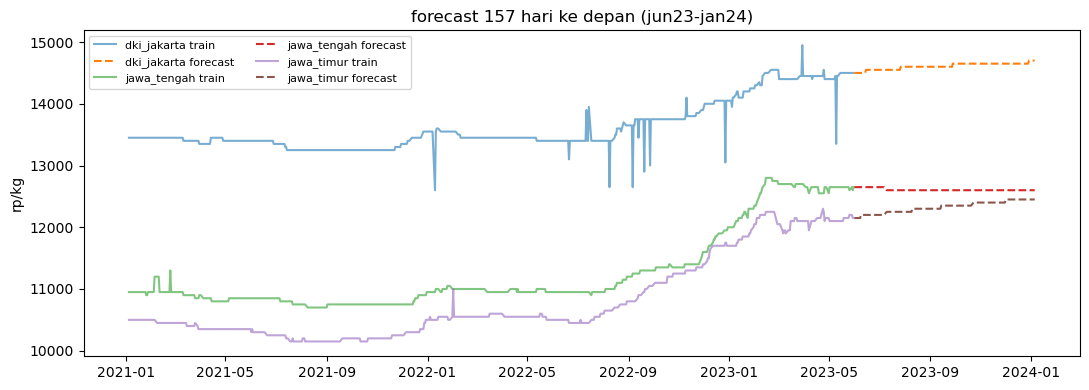

In [ ]:

H = len(test)
preds = {}
for c in targets:
    a, b, p = best_cfg[c]['holt']
    N, d = best_cfg[c]['drift']
    h = holt(df[c], H, a, b, p)
    r = drift(df[c], H, N, d)
    preds[c] = round50((h + r) / 2)
sub = pd.DataFrame({'id': test['id'].values, **preds})
sub.to_csv('submission_rice_forecast.csv', index=False)
print(sub.head(10).to_string(index=False))
print('...')
print(sub.tail(5).to_string(index=False))
print('header:', list(sub.columns), 'shape:', sub.shape)

fig, ax = plt.subplots(figsize=(11, 4))
for c in targets:
    ax.plot(df['date'], df[c], alpha=0.6, label=c + ' train')
    ax.plot(pd.to_datetime(test['date']), preds[c], '--', label=c + ' forecast')
ax.legend(ncol=2, fontsize=8); ax.set_title('forecast 157 hari ke depan (jun23-jan24)')
ax.set_ylabel('rp/kg'); plt.tight_layout(); plt.show()